In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


cols = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(
    r"E:/Machine-Learning/project/iris-classification\data/iris.data",
    header=None,
    names=cols
)

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
print('Shape:',df.shape),
print("\n Detatype"),
print(df.dtypes),
print("\nMissing values:"),
print(df.isnull().sum()),
print("\nSpecies:"),
print(df["species"].unique()),

Shape: (150, 5)

 Detatype
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


(None,)

In [7]:
df["species"].value_counts()
df["species"].value_counts(normalize=True) * 100
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


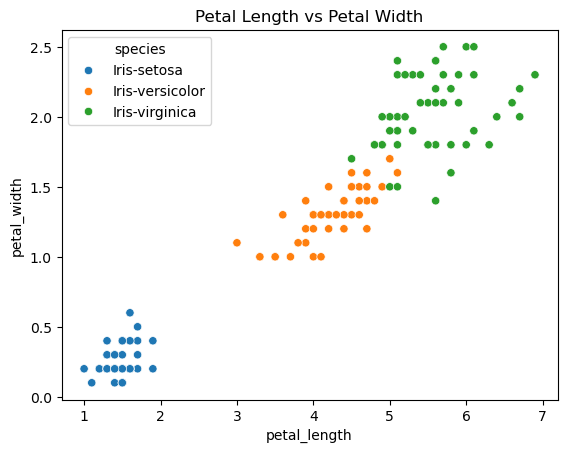

In [8]:
sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species"
)
plt.title("Petal Length vs Petal Width")
plt.show()

In [9]:
# Features: ویژگی‌هایی که مدل از آن‌ها یاد می‌گیرد
X = df[["petal_length", "petal_width"]]

# Target: چیزی که مدل باید پیش‌بینی کند
y = df["species"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (150, 2)
y shape: (150,)


,petal_length,petal_width
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


In [10]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training samples:", x_train.shape[0])
print("Testing samples:", x_test.shape[0])

Training samples: 120
Testing samples: 30


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

model=KNeighborsClassifier(n_neighbors=3)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)
accuracy=accuracy_score(y_test,y_pred)

print("Accuracy:",accuracy)

Accuracy: 0.9666666666666667


In [12]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(x_train, y_train)

baseline_pred = baseline.predict(x_test)

print("Baseline accuracy:", accuracy_score(y_test, baseline_pred))
print("KNN accuracy:", accuracy_score(y_test, y_pred))

Baseline accuracy: 0.3333333333333333
KNN accuracy: 0.9666666666666667


In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

scores = cross_val_score(
    knn,
    x_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Fold scores:", scores)
print("Mean CV accuracy:", scores.mean())

Fold scores: [0.91666667 0.95833333 0.95833333 0.95833333 1.        ]
Mean CV accuracy: 0.9583333333333334


In [15]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC()
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    print(f"{name}: {scores.mean():.4f}")

KNN: 0.9583
Logistic Regression: 0.9667
Decision Tree: 0.9500
Random Forest: 0.9500
SVM: 0.9750


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC())
])

model.fit(x_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

models = {
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC()
}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        pipeline,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print(f"{name}: {scores.mean():.4f}")

KNN: 0.9500
Logistic Regression: 0.9583
SVM: 0.9667


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC())
])

final_model.fit(x_train, y_train)

y_pred_final = final_model.predict(x_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final))

Test accuracy: 0.9333333333333333
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



In [19]:
import joblib

joblib.dump(final_model, "iris_svm_pipeline.joblib")
print("Model saved successfully!")

Model saved successfully!


In [20]:
import joblib

loaded_model = joblib.load("iris_svm_pipeline.joblib")

sample = [[1.4, 0.2]]
prediction = loaded_model.predict(sample)

print("Predicted species:", prediction[0])

Predicted species: Iris-setosa


c:\Users\LAPTOP PLAZA\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [21]:
import sklearn
import pandas
import numpy
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.7.2
pandas: 2.3.3
numpy: 2.3.5
joblib: 1.5.2
